In [105]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [106]:
cpu=pd.read_csv('/content/drive/MyDrive/vm_cpu_readings.csv')
meta=pd.read_csv('/content/drive/MyDrive/vm_metadata.csv')

In [107]:
cpu.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1340000 entries, 0 to 1339999
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   timestamp  1340000 non-null  int64  
 1   vm_id      1340000 non-null  object 
 2   min_cpu    1340000 non-null  float64
 3   max_cpu    1340000 non-null  float64
 4   avg_cpu    1340000 non-null  float64
dtypes: float64(3), int64(1), object(1)
memory usage: 51.1+ MB


In [108]:
meta.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vm_id                 10000 non-null  object 
 1   subscription_id       10000 non-null  object 
 2   deployment_id         10000 non-null  object 
 3   timestamp_vm_created  10000 non-null  int64  
 4   timestamp_vm_deleted  10000 non-null  int64  
 5   max_cpu               10000 non-null  float64
 6   avg_cpu               10000 non-null  float64
 7   p95_max_cpu           10000 non-null  float64
 8   vm_category           10000 non-null  object 
 9   virtual_core_bucket   10000 non-null  object 
 10  memory_gb_bucket      10000 non-null  object 
dtypes: float64(3), int64(2), object(6)
memory usage: 859.5+ KB


In [109]:
cpu['vm_id'].shape

(1340000,)

In [110]:
print('total unique timestamps in the cpu:',cpu['timestamp'].nunique())

total unique timestamps in the cpu: 134


In [111]:
print('the number of null vlaues in the cpu :',cpu.isnull().sum())

the number of null vlaues in the cpu : timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64


In [112]:
print('the number of duplicates vlaues in the cpu :',cpu.duplicated().sum())

the number of duplicates vlaues in the cpu : 0


In [113]:
print('check unique VM_ID in cpu data :',cpu['vm_id'].nunique())

check unique VM_ID in cpu data : 10000


In [114]:
cpu['avg_cpu'].isnull().sum()

np.int64(0)

In [115]:
print('shape of the meta data:',meta.shape)

shape of the meta data: (10000, 11)


In [116]:
print('check present of null values:',meta.isnull().sum())

check present of null values: vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64


In [117]:
numerical=cpu[['timestamp','min_cpu','max_cpu','avg_cpu']]

In [118]:
cpu.groupby(['timestamp'])['avg_cpu'].mean()

,avg_cpu
timestamp,
0,9.396898
300,9.353775
600,9.454383
900,9.224419
1200,9.143503
...,...
38700,9.430236
39000,9.307138
39300,9.499973


In [119]:
cpu['timestamp'].unique()

array([    0,   300,   600,   900,  1200,  1500,  1800,  2100,  2400,
        2700,  3000,  3300,  3600,  3900,  4200,  4500,  4800,  5100,
        5400,  5700,  6000,  6300,  6600,  6900,  7200,  7500,  7800,
        8100,  8400,  8700,  9000,  9300,  9600,  9900, 10200, 10500,
       10800, 11100, 11400, 11700, 12000, 12300, 12600, 12900, 13200,
       13500, 13800, 14100, 14400, 14700, 15000, 15300, 15600, 15900,
       16200, 16500, 16800, 17100, 17400, 17700, 18000, 18300, 18600,
       18900, 19200, 19500, 19800, 20100, 20400, 20700, 21000, 21300,
       21600, 21900, 22200, 22500, 22800, 23100, 23400, 23700, 24000,
       24300, 24600, 24900, 25200, 25500, 25800, 26100, 26400, 26700,
       27000, 27300, 27600, 27900, 28200, 28500, 28800, 29100, 29400,
       29700, 30000, 30300, 30600, 30900, 31200, 31500, 31800, 32100,
       32400, 32700, 33000, 33300, 33600, 33900, 34200, 34500, 34800,
       35100, 35400, 35700, 36000, 36300, 36600, 36900, 37200, 37500,
       37800, 38100,

In [120]:
cpu[['avg_cpu','timestamp']].tail(5)

,avg_cpu,timestamp
1339995,5.993970,39900
1339996,8.539113,39900
1339997,14.746790,39900
1339998,4.033910,39900
1339999,5.367855,39900


In [121]:
targets=pd.DataFrame({
    'active_vm_count(t)':cpu.groupby(['timestamp'])['vm_id'].nunique(),
    'aggregate_cpu_utilization(t)': cpu.groupby(['timestamp'])['avg_cpu'].mean()
})

In [122]:
targets

,active_vm_count(t),aggregate_cpu_utilization(t)
timestamp,,
0,10000,9.396898
300,10000,9.353775
600,10000,9.454383
900,10000,9.224419
1200,10000,9.143503
...,...,...
38700,10000,9.430236
39000,10000,9.307138
39300,10000,9.499973


In [123]:
targets['aggregate_cpu_utilization(t)'].unique().sum()

np.float64(1258.005497742525)

In [124]:
cpu.groupby(['min_cpu','max_cpu','timestamp'])['avg_cpu'].max()

min_cpu    max_cpu    timestamp
0.000000   91.478581  15300        14.994944
           91.762486  27600        10.825511
           92.701332  3000         23.553888
           93.181166  35700        14.901943
           93.463815  7200         37.546699
                                     ...    
99.271093  99.479592  27300        99.370173
99.274802  99.326909  1500         99.300856
99.277064  99.327823  37200        99.296881
99.281581  99.328465  26400        99.302613
99.281582  99.449189  30300        99.350097
Name: avg_cpu, Length: 1340000, dtype: float64

In [125]:
print(f'the average cpu uitization at max is :{cpu['avg_cpu'].max():2f},with index number:{cpu['avg_cpu'].idxmax()}')
print(f'the average cpu uitization at min is :{cpu['avg_cpu'].min():2f},with index number:{cpu['avg_cpu'].idxmin()}')

the average cpu uitization at max is :99.488027,with index number:150891
the average cpu uitization at min is :0.007159,with index number:454649


In [126]:
print(cpu.groupby(['timestamp'])['avg_cpu'].max())
print('*'*50)
print(cpu.groupby(['timestamp'])['avg_cpu'].min())

timestamp
0        99.289025
300      99.399598
600      99.300530
900      99.312643
1200     99.300614
           ...    
38700    99.276729
39000    99.286548
39300    99.278561
39600    99.293207
39900    99.220609
Name: avg_cpu, Length: 134, dtype: float64
**************************************************
timestamp
0        0.007373
300      0.007350
600      0.007474
900      0.007353
1200     0.007401
           ...   
38700    0.007559
39000    0.007478
39300    0.007573
39600    0.007520
39900    0.007687
Name: avg_cpu, Length: 134, dtype: float64


In [127]:
idle=(cpu['avg_cpu']<=5).mean()*100
print(f'the Reading percentage which are idle is around:{idle:.2f}%')
maximum_utilization=(cpu['avg_cpu']>90).mean()*100
print(f'the Reading percentage which are max :{maximum_utilization:.2f}% ')
regular=(cpu['avg_cpu'].between(20,80)).mean()*100
print(f'the regular Reading are:{regular:.2f}')

the Reading percentage which are idle is around:49.05%
the Reading percentage which are max :0.88% 
the regular Reading are:8.49


In [128]:
category=pd.cut(
    x=cpu['avg_cpu'],
    bins=[0,5,20,80,95,100],
    labels=['idle(0-5)','low(5-20)','Moderate(20-80)','HIGH(80-95)','Very_high(95-100)'],
    include_lowest=True
)
print(f'the category wise usage of the cpu are as:{category.value_counts().sort_index()}')

the category wise usage of the cpu are as:avg_cpu
idle(0-5)            657263
low(5-20)            551935
Moderate(20-80)      113796
HIGH(80-95)            9356
Very_high(95-100)      7650
Name: count, dtype: int64


Text(0.5, 1.0, 'CPU Utilization in different Bands')

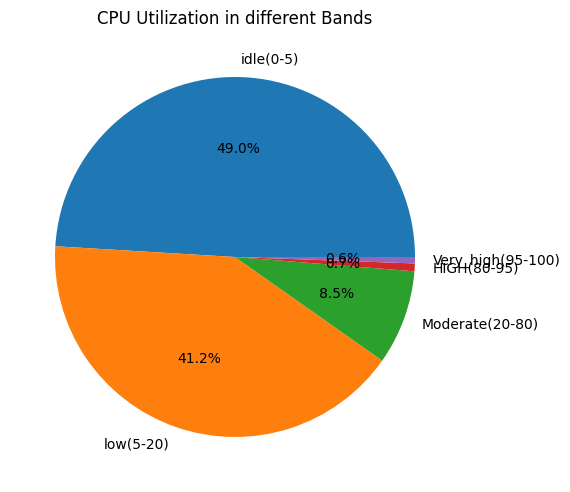

In [129]:
category_counts=category.value_counts().sort_index()
plt.pie(x=category_counts,autopct='%1.1f%%',labels=category_counts.index)
plt.tight_layout()
plt.title('CPU Utilization in different Bands')

In [130]:
total=pd.DataFrame({
    'Readings':category_counts,
    'share_%': category_counts/len(cpu)*100
})
total

,Readings,share_%
avg_cpu,,
idle(0-5),657263,49.049478
low(5-20),551935,41.189179
Moderate(20-80),113796,8.492239
HIGH(80-95),9356,0.698209
Very_high(95-100),7650,0.570896


In [131]:
overall_cpu_used=cpu['avg_cpu'].mean()
overall_cpu_idel=100-overall_cpu_used
print(f'the Average CPU used is :{overall_cpu_used:.2f}\n The average CPU idle is {overall_cpu_idel:.2f}')

the Average CPU used is :9.39
 The average CPU idle is 90.61


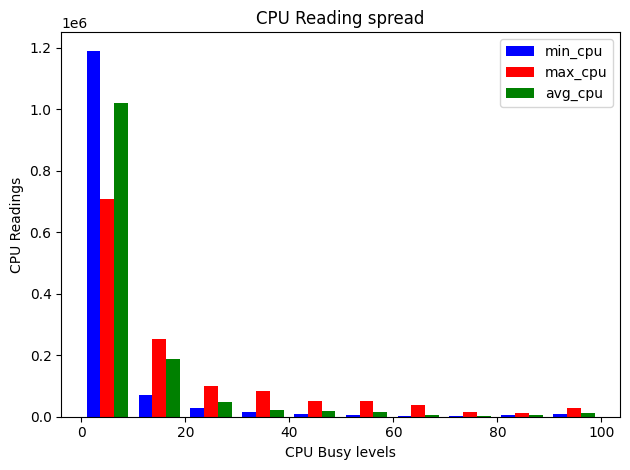

In [132]:
plt.hist(x=cpu[['min_cpu','max_cpu','avg_cpu']],color=['blue','red','green'],label=['min_cpu','max_cpu','avg_cpu'],bins=10)
plt.title('CPU Reading spread')
plt.xlabel('CPU Busy levels')
plt.ylabel('CPU Readings')
plt.tight_layout()
plt.legend()
plt.show()

the most VMs are idle , can see in the pie chart . the around 1% CPU are have high usage. from histplot we can see the first (0-10) the min_cpu are most . but after that the max_cpu or we can say that the usage of the cpu is almost high from the avgerage usage and idle . this is the shift of the cpu usage we can see through it .

In [133]:
print(targets.describe())
print(targets.isna().sum())
print(targets["active_vm_count(t)"].nunique())

       active_vm_count(t)  aggregate_cpu_utilization(t)
count               134.0                    134.000000
mean              10000.0                      9.388101
std                   0.0                      0.194987
min               10000.0                      8.983613
25%               10000.0                      9.250956
50%               10000.0                      9.367252
75%               10000.0                      9.485657
max               10000.0                      9.912175
active_vm_count(t)              0
aggregate_cpu_utilization(t)    0
dtype: int64
1


<Axes: ylabel='aggregate_cpu_utilization(t)'>

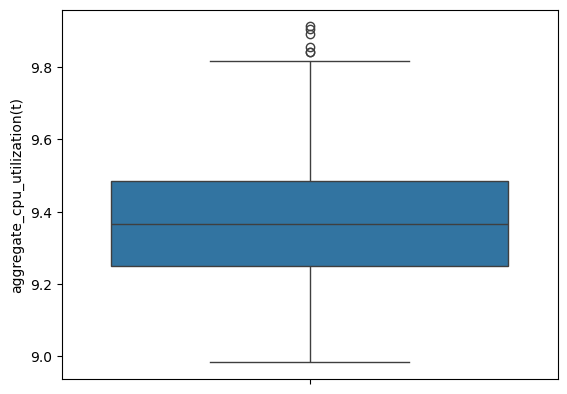

In [134]:
sns.boxplot(data=targets,y=targets['aggregate_cpu_utilization(t)'])

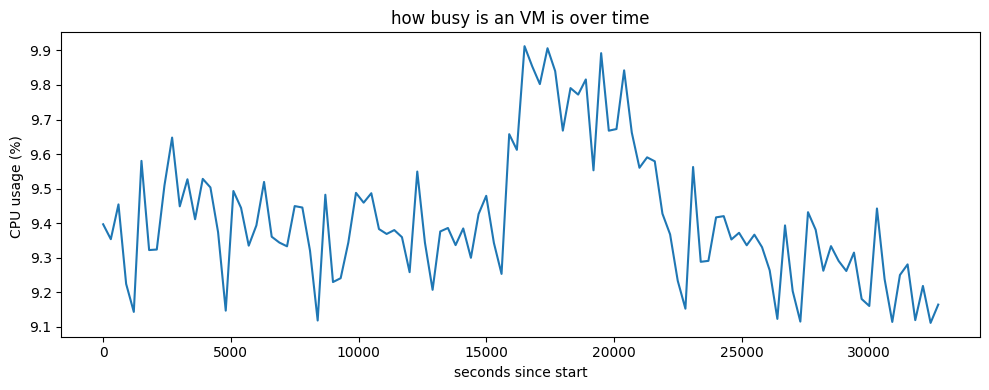

In [135]:
targets["aggregate_cpu_utilization(t)"].iloc[:110].plot(figsize=(10, 4))
plt.title('how busy is an VM is over time')
plt.ylabel('CPU usage (%) ')
plt.xlabel('seconds since start')
plt.tight_layout()

# **The average CPU usage of all VMs not very much , so most CPU capacity is unused**

In [136]:
meta['vm_category'].isna().sum()
group1=meta.groupby(['vm_category'])['avg_cpu'].agg(
    Mean='mean',Median='median',Count='count')
group1


,Mean,Median,Count
vm_category,,,
Delay-insensitive,8.165126,5.882293,6180
Interactive,11.435729,6.083141,3091
Unknown,10.389816,4.033370,729


In [137]:
read=meta.groupby(['vm_category'])['avg_cpu'].quantile([0.10,0.25,0.50,.75,0.90,0.95]).unstack()
read.columns=['10%','25%','50%','75%','90%','95%']
print(read.round(2))

                    10%   25%   50%    75%    90%    95%
vm_category                                             
Delay-insensitive  1.56  2.95  5.88  10.03  14.67  23.62
Interactive        1.83  3.68  6.08  13.59  28.71  46.77
Unknown            0.88  1.58  4.03  10.38  30.80  47.46


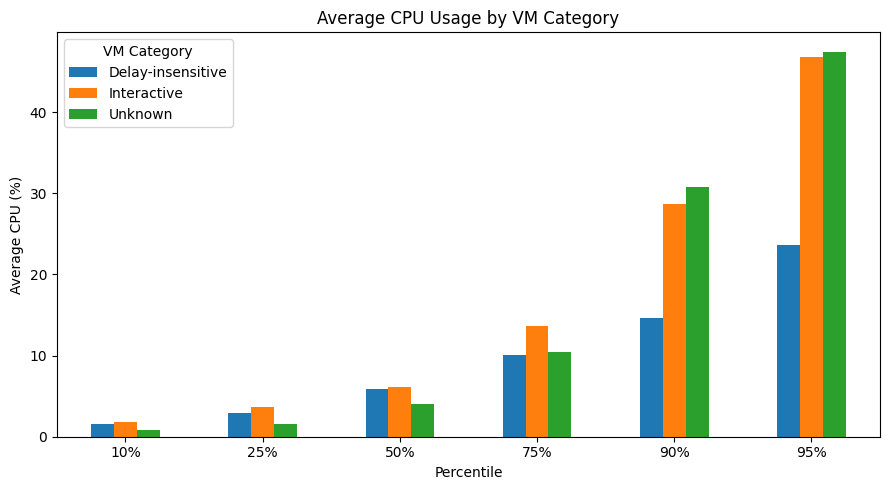

In [178]:
read.T.plot(kind='bar', figsize=(9, 5))

plt.title('Average CPU Usage by VM Category')
plt.xlabel('Percentile')
plt.ylabel('Average CPU (%)')
plt.xticks(rotation=0)
plt.legend(title='VM Category')
plt.tight_layout()
plt.show()

<Axes: xlabel='count', ylabel='vm_category'>

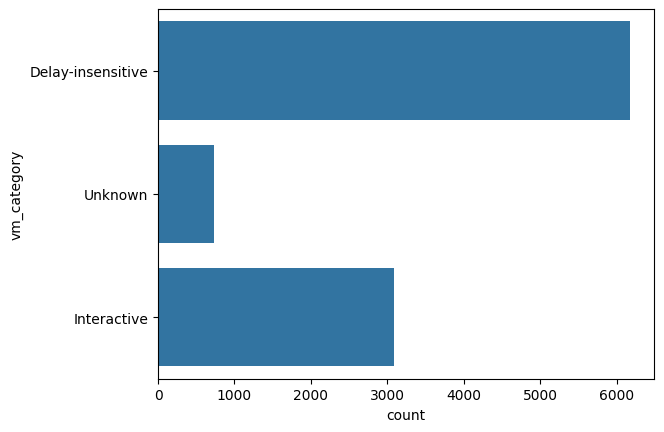

In [139]:
sns.countplot(data=meta['vm_category'])

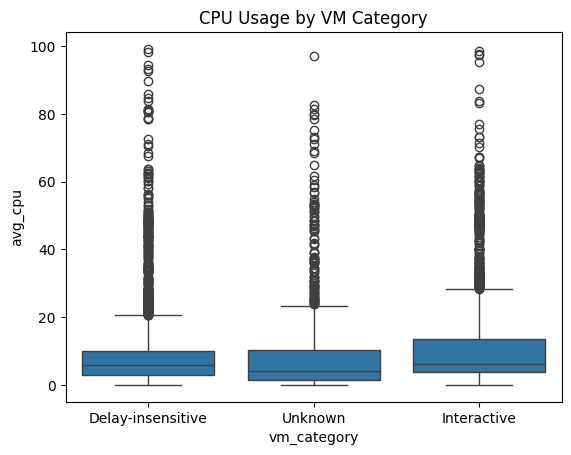

In [140]:
sns.boxplot(data=meta,x=meta['vm_category'],y=meta['avg_cpu'])
plt.title('CPU Usage by VM Category')
plt.show()

In [141]:
deleted=meta['timestamp_vm_deleted']
deleted.describe()

,timestamp_vm_deleted
count,1.000000e+04
mean,2.289626e+06
std,7.081008e+05
min,4.050000e+04
25%,2.591400e+06
50%,2.591400e+06
75%,2.591400e+06
max,2.591400e+06


In [142]:
meta['timestamp_vm_created'].value_counts()

,count
timestamp_vm_created,
0,10000


In [143]:
meta['vm_category'].value_counts()

,count
vm_category,
Delay-insensitive,6180
Interactive,3091
Unknown,729


In [144]:
peak=cpu['avg_cpu'].quantile(0.90)
low=cpu['avg_cpu'].quantile(0.10)
peak_target=targets['aggregate_cpu_utilization(t)'].iloc[:110].quantile(0.90)
low_target=targets['aggregate_cpu_utilization(t)'].iloc[:110].quantile(0.10)

print('the peak moment of cpu:',peak)
print('the low moment of cpu:',low)
print('the peak moment of cpu in targets :',peak_target)
print('the low moment of cpu in targets :',low_target)

the peak moment of cpu: 19.6014544000585
the low moment of cpu: 1.23355056989628
the peak moment of cpu in targets : 9.668361517488389
the low moment of cpu in targets : 9.179197770908909


In [145]:
targets.to_csv('targets.csv')

In [146]:
train_data=targets.iloc[:-24]
holdout=targets.iloc[-24:]

In [147]:
print(len(train_data))
print(len(holdout))

110
24


In [148]:
data={}
lag=6
for i in range(1,lag+1):
  column_name=f'lag{i}'
  shifted_values=train_data['aggregate_cpu_utilization(t)'].shift(i)
  data[column_name]=shifted_values

df=pd.DataFrame(data)

In [149]:
df=df.dropna()

In [150]:
df['y']=train_data['aggregate_cpu_utilization(t)']

In [151]:
df

,lag1,lag2,lag3,lag4,lag5,lag6,y
timestamp,,,,,,,
1800,9.580335,9.143503,9.224419,9.454383,9.353775,9.396898,9.322337
2100,9.322337,9.580335,9.143503,9.224419,9.454383,9.353775,9.323858
2400,9.323858,9.322337,9.580335,9.143503,9.224419,9.454383,9.509058
2700,9.509058,9.323858,9.322337,9.580335,9.143503,9.224419,9.647704
3000,9.647704,9.509058,9.323858,9.322337,9.580335,9.143503,9.448768
...,...,...,...,...,...,...,...
31500,9.250152,9.114320,9.237916,9.442585,9.160524,9.180825,9.280858
31800,9.280858,9.250152,9.114320,9.237916,9.442585,9.160524,9.119565
32100,9.119565,9.280858,9.250152,9.114320,9.237916,9.442585,9.218538


In [152]:
x=df.drop(columns=['y']).values
y=df['y'].values

In [153]:
print(len(x))
print(len(y))

104
104


In [154]:
x.shape

(104, 6)

In [155]:
from sklearn.model_selection import TimeSeriesSplit

In [156]:
tcsv=TimeSeriesSplit(n_splits=3,test_size=24)

In [157]:
!pip install optuna

In [158]:
import optuna

In [159]:
from sklearn.ensemble import RandomForestRegressor,AdaBoostRegressor
from  sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error,root_mean_squared_error
from sklearn.pipeline import make_pipeline

In [160]:
def objectives(trails):
  model_select=trails.suggest_categorical('models',['Forest_Reg','Ada_Reg','XG_Reg','SVM'])

  if model_select=='Forest_Reg':
    n_estimator=trails.suggest_int('forest',1,100)
    depth=trails.suggest_int('fores_dept',1,25)
    model=RandomForestRegressor(n_estimators=n_estimator,random_state=42,max_depth=depth)
  elif model_select=='Ada_Reg':
    n_estimator=trails.suggest_int('ada',1,100)
    learning_rate=trails.suggest_float('lr',0.001,1,log=True)
    depth=trails.suggest_int('ada_dept',1,20)
    stump=DecisionTreeRegressor(max_depth=depth)
    model=AdaBoostRegressor(estimator=stump,learning_rate=learning_rate,n_estimators=n_estimator,random_state=42)

  elif model_select=='XG_Reg':
    n_estimator=trails.suggest_int('xg',1,100)
    learning_xg=trails.suggest_float('xg_lr',0.001,1,log=True)
    model=XGBRegressor(learning_rate=learning_xg,n_estimators=n_estimator,random_state=42)
  elif model_select=='SVM':
    ker=trails.suggest_categorical('kernel',['linear', 'rbf', 'poly', 'sigmoid'])
    epsilon = trails.suggest_float(
        'svr_epsilon', 0.01, 1.0, log=True)
    C=trails.suggest_float('svr_C', 0.01, 100, log=True)
    model=make_pipeline(
        SVR(kernel=ker, epsilon=epsilon, C=C)
    )


  maes=[]
  rmse=[]

  for fit_indx,val_indx in tcsv.split(x):
    model.fit(x[fit_indx],y[fit_indx])
    pred=model.predict(x[val_indx])
    maes.append(mean_absolute_error(y[val_indx],pred))
    rmse.append(root_mean_squared_error(y[val_indx],pred))

  return np.mean(maes)

In [161]:
from optuna.samplers import TPESampler
study=optuna.create_study(direction='minimize',sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objectives,n_trials=50)

[I 2026-10-26 04:19:24,685] A new study created in memory with name: no-name-8393672c-7279-446a-ad8d-baf8d0d6b45e
[I 2026-10-26 04:19:24,758] Trial 0 finished with value: 0.1470075335620253 and parameters: {'models': 'Ada_Reg', 'ada': 16, 'lr': 0.0029375384576328283, 'ada_dept': 2}. Best is trial 0 with value: 0.1470075335620253.
[I 2026-10-26 04:19:25,424] Trial 1 finished with value: 0.14314644929863618 and parameters: {'models': 'Forest_Reg', 'forest': 97, 'fores_dept': 21}. Best is trial 1 with value: 0.14314644929863618.
[I 2026-10-26 04:19:25,436] Trial 2 finished with value: 0.1816984885485514 and parameters: {'models': 'SVM', 'kernel': 'sigmoid', 'svr_epsilon': 0.01901024531987036, 'svr_C': 0.14742753159914673}. Best is trial 1 with value: 0.14314644929863618.
[I 2026-10-26 04:19:25,551] Trial 3 finished with value: 0.14841014500307415 and parameters: {'models': 'XG_Reg', 'xg': 52, 'xg_lr': 0.05987474910461398}. Best is trial 1 with value: 0.14314644929863618.
[I 2026-10-26 04:

In [162]:
print(study.best_value)
print(study.best_params)
print(study.best_trial)

0.13924757123906972
{'models': 'SVM', 'kernel': 'rbf', 'svr_epsilon': 0.07786935956912991, 'svr_C': 0.2881367711762892}
FrozenTrial(number=45, state=<TrialState.COMPLETE: 1>, values=[0.13924757123906972], datetime_start=datetime.datetime(2026, 10, 26, 4, 19, 49, 213609), datetime_complete=datetime.datetime(2026, 10, 26, 4, 19, 49, 225454), params={'models': 'SVM', 'kernel': 'rbf', 'svr_epsilon': 0.07786935956912991, 'svr_C': 0.2881367711762892}, user_attrs={}, system_attrs={'tpe:relative_params:0': '{"models": "SVM"}'}, intermediate_values={}, distributions={'models': CategoricalDistribution(choices=('Forest_Reg', 'Ada_Reg', 'XG_Reg', 'SVM')), 'kernel': CategoricalDistribution(choices=('linear', 'rbf', 'poly', 'sigmoid')), 'svr_epsilon': FloatDistribution(high=1.0, log=True, low=0.01, step=None), 'svr_C': FloatDistribution(high=100.0, log=True, low=0.01, step=None)}, trial_id=45, value=None)


In [163]:
df_study=(study.trials_dataframe()
      [['value','params_models']].nsmallest(20,'value')

)

In [164]:
df_study.sort_values(ascending=True,by='value').head()

,value,params_models
45,0.139248,SVM
46,0.139775,SVM
47,0.139955,SVM
48,0.141487,SVM
22,0.142077,Forest_Reg


In [165]:
from optuna.visualization import   plot_param_importances,plot_parallel_coordinate

In [166]:
plot_parallel_coordinate(study)

In [167]:
plot_param_importances(study)

In [168]:
mae=[]
rmse=[]

for _,val_indx in tcsv.split(x):
  pred=x[val_indx,0]
  mae.append(mean_absolute_error(y[val_indx],pred))
  rmse.append(root_mean_squared_error(y[val_indx],pred))

print(f'the MAE of the baseline:{np.mean(mae)}')
print(f'the RMSE of the baseline:{np.mean(rmse)}')


the MAE of the baseline:0.11758056474645372
the RMSE of the baseline:0.15279350496299518


In [169]:
y_test = train_data['aggregate_cpu_utilization(t)'].values
seek = y_test[:86]
check = y_test[86:]

naive_base = np.repeat(seek[-1], 24)
mean_base = np.repeat(seek.mean(), 24)

x_lag= []
t_lag= []
lag = 6

for i in range(lag, len(seek)):
    x_lag.append(seek[i-lag:i])
    t_lag.append(seek[i])

model = SVR(
    kernel=study.best_params['kernel'],
    epsilon=study.best_params['svr_epsilon'],C=study.best_params['svr_C']

)
model.fit(x_lag, t_lag)

history = list(seek)
pred = []

for i in range(24):
    l = history[-6:]
    prediction = model.predict([l])[0]
    history.append(prediction)
    pred.append(prediction)

print('Naive MAE:', mean_absolute_error(check, naive_base))
print('Mean MAE:', mean_absolute_error(check, mean_base))
print('SVR MAE:', mean_absolute_error(check, pred))

Naive MAE: 0.13242942454439147
Mean MAE: 0.21049225651251127
SVR MAE: 0.10926252371998009


In [170]:
vm_col= 'active_vm_count(t)'
cpu_col='aggregate_cpu_utilization(t)'

train_part=targets.iloc[:110]
holdout_part=targets.iloc[110:]
print(len(holdout_part))
print(len(train_part))

preds=pd.DataFrame({
    'timestamp':holdout_part.index,
    'active_vm_count':np.repeat(train_part[vm_col].iloc[-1],24),
    'aggregate_cpu_utilization':np.repeat(train_part[cpu_col].iloc[-1],24)

})
preds.to_csv('predictions.csv', index=False)
print(preds.head(3))
print(preds.shape)

24
110
   timestamp  active_vm_count  aggregate_cpu_utilization
0      33000            10000                   9.164556
1      33300            10000                   9.164556
2      33600            10000                   9.164556
(24, 3)


In [171]:
h=24
series=targets['aggregate_cpu_utilization(t)'].iloc[:-h]

actual_list,forcast_list,step_list=[],[],[]

for start in range(30,len(series)-h+1):
  last_value=series.iloc[start-1]
  for i in range(1,h+1):
    actual_list.append(series.iloc[start+i-1])
    forcast_list.append(last_value)
    step_list.append(i)

# print(f'{len(actual_list)}')

actual_arr=np.array(actual_list)
forcast_arr=np.array(forcast_list)
step_arr=np.array(step_list)
error=actual_arr-forcast_arr
q1=series.quantile(0.90)
q2=series.quantile(0.10)

print(f'MAE:{round(np.abs(error).mean(),2)},\nRMSE:{round(np.sqrt((error ** 2).mean()) ,2)}')
print('Error:',error.mean())

print(f'THE peak limit:{round(q1,2)},\nTHE low limit:{round(q2,2)}')
print('margin 90%:', round(np.quantile(error, 0.90), 2))
print('margin 95%:', round(np.quantile(error, 0.95), 2))

peak,low=actual_arr>q1,actual_arr<q2
normal=(actual_arr<q1) & (actual_arr>q2)

print("Peak MAE:", round(np.abs(error[peak]).mean(), 2))
print("Low MAE:", round(np.abs(error[low]).mean(), 2))
print("Normal MAE:", round(np.abs(error[normal]).mean(), 2))

MAE:0.23,
RMSE:0.29
Error: -0.02313537897248724
THE peak limit:9.67,
THE low limit:9.18
margin 90%: 0.41
margin 95%: 0.5
Peak MAE: 0.35
Low MAE: 0.36
Normal MAE: 0.19
